# Statistics within groups: `groupby`

**Lecture 10 · Wednesday, 18 November 2026 · Notebook 2 of 3 (Video 10B)**

We return to the employment rates of Danish municipalities from Lecture 9. Many questions are about **groups**: the average across municipalities in each year, or the change within each municipality over time. `groupby` answers them in one line each.

**Table of contents**<a id='toc0_'></a>
- 1. [Split, apply, combine](#toc1_)
- 2. [Several statistics at once](#toc2_)
- 3. [Changes within a group](#toc3_)
- 4. [Back to every row: `transform`](#toc4_)
- 5. [Who recovered most after the financial crisis?](#toc5_)
- 6. [Summary](#toc6_)

<a id='video-10b'></a>
> **Start Video 10B**  
> Question: how did the average municipality move through the financial crisis?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/RAS200.csv')
df = df.sort_values(['municipality', 'year']).reset_index(drop=True)
df.head()

,municipality,year,emp_rate,part_rate
0,Aabenraa,2008,74.6,76.3
1,Aabenraa,2009,71.6,75.2
2,Aabenraa,2010,70.9,74.5
3,Aabenraa,2011,70.2,74.0
4,Aabenraa,2012,69.5,73.7


## 1. <a id='toc1_'></a>[Split, apply, combine](#toc0_)

`df.groupby('year')['emp_rate'].mean()` does three things:

1. **split** the rows into groups, one per year;
2. **apply** a calculation, here the mean, to each group;
3. **combine** the results into one table, with the group as index.

In Lecture 9 this took a loop over years; now it is one line.

In [2]:
mean_by_year = df.groupby('year')['emp_rate'].mean()
mean_by_year.round(2)

year
2008    76.63
2009    73.42
2010    72.79
2011    72.59
2012    72.02
2013    72.09
2014    72.43
2015    72.88
2016    73.67
2017    74.46
2018    75.46
2019    76.00
2020    75.48
2021    77.73
2022    78.19
2023    78.12
Name: emp_rate, dtype: float64

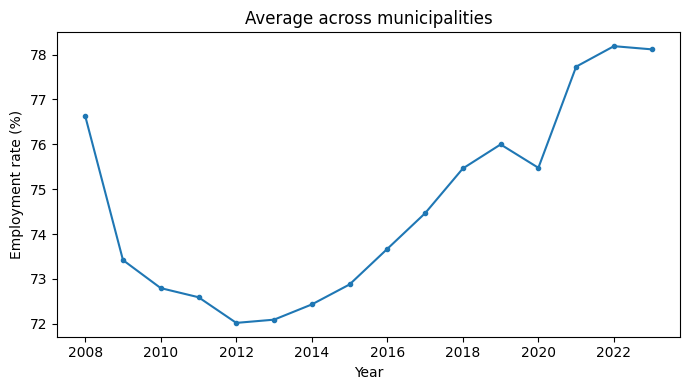

In [3]:
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(mean_by_year.index, mean_by_year.values, marker='.')
ax.set_xlabel('Year')
ax.set_ylabel('Employment rate (%)')
ax.set_title('Average across municipalities')
fig.tight_layout()
plt.show()

This is the **unweighted** average of the 99 municipalities: tiny Læsø counts as much as Copenhagen. It is not the employment rate of Denmark as a whole.

Grouping by municipality instead gives one number per municipality:

In [4]:
df.groupby('municipality')['emp_rate'].mean().head()

municipality
Aabenraa       72.51250
Aalborg        70.81250
Aarhus         70.24375
Albertslund    70.20000
Allerød        82.26250
Name: emp_rate, dtype: float64

## 2. <a id='toc2_'></a>[Several statistics at once](#toc0_)

`.agg([...])` applies several functions and gives one column each.

In [5]:
stats = df.groupby('municipality')['emp_rate'].agg(['mean', 'min', 'max'])
stats['range'] = stats['max'] - stats['min']
stats.sort_values('range', ascending=False).head()

,mean,min,max,range
municipality,,,,
Christiansø,74.34375,62.9,83.0,20.1
Læsø,70.79375,66.2,76.3,10.1
Kerteminde,72.85625,68.3,77.6,9.3
Samsø,72.20625,68.2,77.5,9.3
Ærø,68.08750,64.7,73.5,8.8


## 3. <a id='toc3_'></a>[Changes within a group](#toc0_)

The yearly change in the employment rate is `diff()`: each row minus the row above. But the rows of different municipalities sit on top of each other.

**Pause and predict:** what goes wrong in the first row of Aalborg, which follows the last row of Aabenraa?

In [6]:
df['change_wrong'] = df['emp_rate'].diff()
df['change'] = df.groupby('municipality')['emp_rate'].diff()
df.loc[14:17, ['municipality', 'year', 'emp_rate', 'change_wrong', 'change']]

,municipality,year,emp_rate,change_wrong,change
14,Aabenraa,2022,75.6,0.1,0.1
15,Aabenraa,2023,75.3,-0.3,-0.3
16,Aalborg,2008,73.2,-2.1,NaN
17,Aalborg,2009,70.1,-3.1,-3.1


Without `groupby`, Aalborg 2008 is compared with **Aabenraa 2023**: a meaningless number. Within groups, the first year of each municipality correctly has no previous year (`NaN`). **Whenever a calculation looks at neighbouring rows, group first.**

In [7]:
df = df.drop(columns=['change_wrong'])
print('Largest one-year fall:')
df.sort_values('change').head(3)[['municipality', 'year', 'change']]

Largest one-year fall:


,municipality,year,change
929,Læsø,2009,-6.1
545,Hedensted,2009,-4.9
1393,Sønderborg,2009,-4.8


## 4. <a id='toc4_'></a>[Back to every row: `transform`](#toc0_)

`.mean()` returns **one row per group**. `.transform(...)` returns the group result **on every row**, so it can be used in a new column.

Example: index each municipality's employment rate to its own 2008 level, 2008 = 100. `transform('first')` puts each municipality's first value on all its rows.

In [8]:
df['emp_2008'] = df.groupby('municipality')['emp_rate'].transform('first')
df['index_2008'] = df['emp_rate']/df['emp_2008']*100
df.loc[14:17, ['municipality', 'year', 'emp_rate', 'emp_2008', 'index_2008']]

,municipality,year,emp_rate,emp_2008,index_2008
14,Aabenraa,2022,75.6,74.6,101.340483
15,Aabenraa,2023,75.3,74.6,100.938338
16,Aalborg,2008,73.2,73.2,100.000000
17,Aalborg,2009,70.1,73.2,95.765027


## 5. <a id='toc5_'></a>[Who recovered most after the financial crisis?](#toc0_)

We compare 2023 with 2008 for every municipality. `.agg` with `first` and `last` picks the first and last year of each group (the data are sorted by year).

In [9]:
recovery = df.groupby('municipality')['emp_rate'].agg(['first', 'last'])
recovery['change'] = recovery['last'] - recovery['first']
recovery = recovery.sort_values('change')

print('Smallest changes 2008-2023:')
print(recovery.head(3))
print('Largest changes 2008-2023:')
print(recovery.tail(3))

Smallest changes 2008-2023:
                first  last  change
municipality                       
Ikast-Brande     79.0  77.3    -1.7
Lyngby-Taarbæk   78.7  77.2    -1.5
Viborg           79.4  78.0    -1.4
Largest changes 2008-2023:
              first  last  change
municipality                     
Bornholm       68.0  74.4     6.4
Samsø          70.8  77.5     6.7
Christiansø    62.9  82.0    19.1


**Before you interpret a ranking, look at the extremes.** Christiansø tops the list with +19 percentage points, but it is a tiny island community: a few people changing jobs move its rate a lot. Bornholm and Samsø follow with about +6.5 points. The same warning appears in the data project.

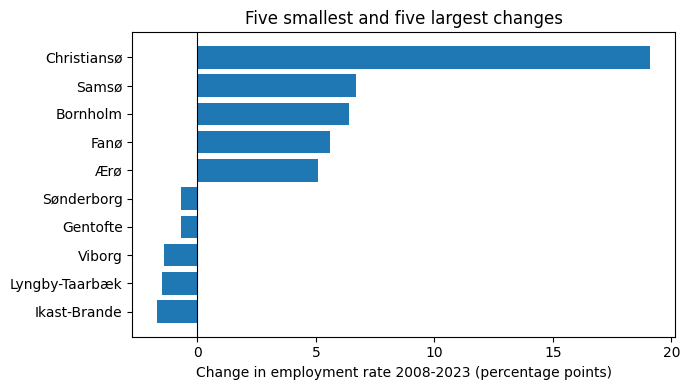

In [10]:
top_bottom = pd.concat([recovery.head(5), recovery.tail(5)])

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.barh(top_bottom.index, top_bottom['change'])
ax.axvline(0.0, color='black', linewidth=0.8)
ax.set_xlabel('Change in employment rate 2008-2023 (percentage points)')
ax.set_title('Five smallest and five largest changes')
fig.tight_layout()
plt.show()

## 6. <a id='toc6_'></a>[Summary](#toc0_)

| Goal | Code | Result |
| --- | --- | --- |
| one number per group | `df.groupby('g')['x'].mean()` | one row per group |
| several statistics | `.agg(['mean', 'min', 'max'])` | one column per statistic |
| change within a group | `df.groupby('g')['x'].diff()` | one value per row |
| group result on every row | `df.groupby('g')['x'].transform('first')` | one value per row |

> **Stop Video 10B.** Next: combining the employment data with income data, in `05_Merge.ipynb`.